# PetPulse · análise exploratória e validação do DBSCAN

**Base simulada de demonstração (Regra 8).** Rode antes `python -m petpulse.pipeline` a partir de `src/`.

In [1]:
import sys, sqlite3
sys.path.insert(0, '../src')
import pandas as pd
from petpulse.config import DB_PATH
conn = sqlite3.connect(DB_PATH)
tel = pd.read_sql('SELECT t.*, d.porte, d.sexo FROM telemetry t JOIN dog d USING(dog_id)', conn, parse_dates=['ts'])
tel.head()

,id,ts,dog_id,zona,lat,lng,h3,kgf,newton,faixa,elev_sensor_m,z_cm,porte,sexo
0,1,2026-11-18 14:57:03,8000,Boulevard Afonso Braz,-23.591065,-46.669224,8aa8100e16f7fff,1.29,13,FROUXA,768.822,27.9,PEQUENO,Macho Inteiro
1,2,2026-11-18 14:57:33,8000,Boulevard Afonso Braz,-23.591032,-46.669227,8aa8100e16f7fff,1.20,12,FROUXA,768.811,28.5,PEQUENO,Macho Inteiro
2,3,2026-11-18 14:58:03,8000,Boulevard Afonso Braz,-23.591029,-46.669245,8aa8100e16f7fff,2.27,22,FROUXA,768.804,24.9,PEQUENO,Macho Inteiro
3,4,2026-11-18 14:58:33,8000,Boulevard Afonso Braz,-23.591021,-46.669242,8aa8100e16f7fff,1.08,11,FROUXA,768.806,29.5,PEQUENO,Macho Inteiro
4,5,2026-11-18 14:59:03,8000,Boulevard Afonso Braz,-23.591008,-46.669253,8aa8100e16f7fff,1.06,10,FROUXA,768.698,23.1,PEQUENO,Macho Inteiro


## Qualidade dos dados

In [2]:
print(tel.shape)
print(tel.isna().sum().sum(), 'valores nulos')
tel[['kgf','newton','z_cm','elev_sensor_m']].describe().round(2)

(36038, 14)
0 valores nulos


,kgf,newton,z_cm,elev_sensor_m
count,36038.00,36038.00,36038.00,36038.00
mean,4.32,42.37,49.79,757.44
std,3.79,37.13,16.82,6.77
min,0.20,2.00,10.30,748.95
25%,1.65,16.00,36.20,752.43
50%,3.14,31.00,49.40,756.40
75%,5.69,56.00,62.40,763.42
max,34.44,338.00,119.70,769.66


## Faixas de guia (Frouxa < 2.5 kgf · Tração 2.5–8 · Tranco > 8)

In [3]:
(tel['faixa'].value_counts(normalize=True)*100).round(1)

faixa
TRACAO    45.2
FROUXA    40.6
TRANCO    14.2
Name: proportion, dtype: float64

## Eixo Z por porte: a mediana deve ficar próxima da altura de referência (28/46/62/78 cm)

In [4]:
tel.groupby('porte')['z_cm'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
porte,,,,,,,,
GIGANTE,3040.0,78.8,6.1,62.6,75.1,78.3,81.7,119.7
GRANDE,11425.0,62.7,6.0,44.3,59.0,62.4,65.9,100.7
MÉDIO,12067.0,46.9,6.1,28.8,43.2,46.5,49.9,89.5
PEQUENO,9506.0,28.6,6.3,10.3,24.7,28.1,31.6,66.9


## Demanda por hora

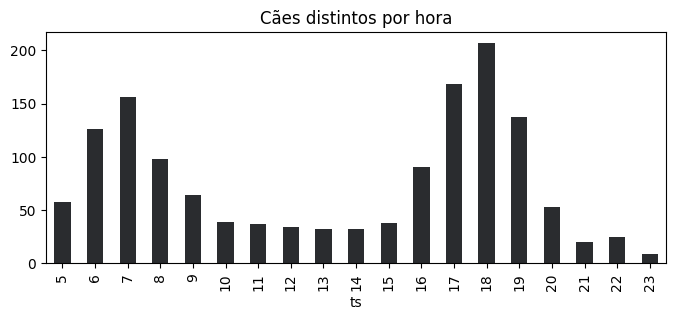

In [5]:
tel.groupby(tel['ts'].dt.hour)['dog_id'].nunique().plot.bar(color='#2A2C2F', figsize=(8,3), title='Cães distintos por hora');

## Clusters públicos (k ≥ 3) por zona

In [6]:
snap = pd.read_sql('SELECT * FROM cluster_snapshot', conn)
snap.groupby('zona').agg(janelas=('dbm','size'), caes_max=('n_caes','max'), dbm_max=('dbm','max')).sort_values('dbm_max', ascending=False)

,janelas,caes_max,dbm_max
zona,,,
Parque Ibirapuera · Portão 7,45,29,71
Parque do Povo · Setor Sul,38,16,62
Praça Pereira Coutinho,34,16,62
Praça Cidade de Milão,28,14,60
Boulevard Afonso Braz,23,11,58
Rua Brazópolis · Vila Nova Conceição,16,9,50


## Sensibilidade do DBSCAN ao ε (metros) numa janela de pico (18h)

In [7]:
from datetime import datetime, timedelta
from petpulse.clustering import ultima_posicao, dbscan
t = datetime(2026,11,18,18,0)
jan = tel[(tel.ts > t - timedelta(minutes=15)) & (tel.ts <= t)]
caes = ultima_posicao(jan)
for eps in (20, 30, 45, 60, 90):
    rot = dbscan(caes, eps_m=eps)
    print(f'eps={eps:>3} m  clusters={len(set(rot)-{-1}):>2}  isolados(ocultos)={(rot==-1).sum():>3}  de {len(caes)} cães')

eps= 20 m  clusters= 6  isolados(ocultos)= 66  de 88 cães
eps= 30 m  clusters= 7  isolados(ocultos)= 49  de 88 cães
eps= 45 m  clusters= 8  isolados(ocultos)= 19  de 88 cães
eps= 60 m  clusters= 6  isolados(ocultos)=  6  de 88 cães
eps= 90 m  clusters= 6  isolados(ocultos)=  0  de 88 cães


**Leitura:** com ε = 45 m os grupos correspondem às zonas reais sem fundir parques vizinhos; ε maiores começam a juntar áreas diferentes e ε menores fragmentam e ocultam cães demais.